C:\Users\Malakai\AppData\Local\Temp\ipykernel_3920\3120097220.py:12: RuntimeWarning: invalid value encountered in sqrt
  return 1 + np.sqrt((r_val+u-U_0)/(r_val+delta))
C:\Users\Malakai\AppData\Local\Temp\ipykernel_3920\3120097220.py:15: RuntimeWarning: invalid value encountered in sqrt
  return 1 - np.sqrt((r_val+u-U_0)/(r_val+delta))


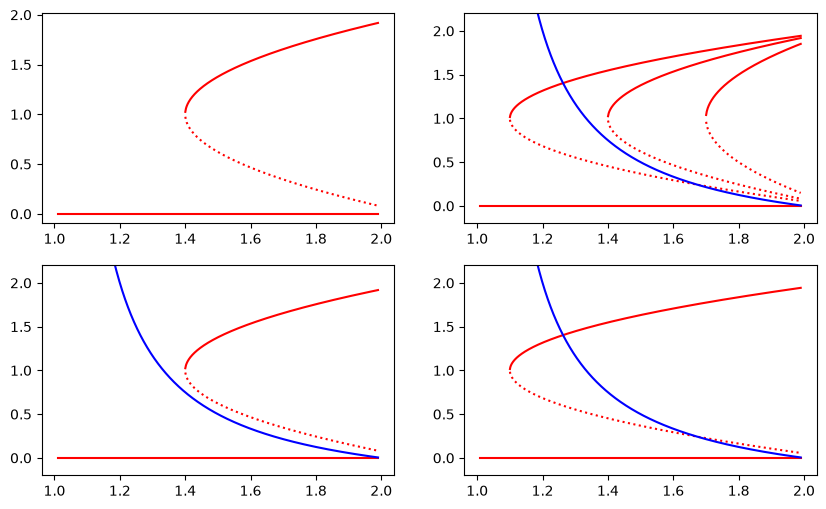

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import odeint
r = [0.3, 0.6, 0.9]
U_0 = 2 #centreline velocity
U_bar = 1 #bulk velocity
delta = 0.1
epsilon_1 = 0.1
epsilon_2 = 0.2

def f(q, u): # q dot
    return q*( r + (u - U_0) - (r + delta)*(q - 1)**2 )

def g(q, u): # u dot
    return epsilon_1*(U_0-u) + epsilon_2(U_bar-u)

def q_nullcline_upper(u, r_val):
    return 1 + np.sqrt((r_val+u-U_0)/(r_val+delta))

def q_nullcline_lower(u, r_val):
    return 1 - np.sqrt((r_val+u-U_0)/(r_val+delta))

def q_nullcline_laminar(u):
    return np.zeros(np.shape(u))

def u_nullcline(u): #correted from equation 8.8 which lacks negative sign
    return -(epsilon_1*(U_0-u))/(epsilon_2*(U_bar - u)) #nullcline is q = this function as plotting in (u, q) phase plane

u_vals = np.linspace(U_bar+0.01, U_0-0.01, 1001)
t_vals = np.linspace(0, 50, 1001)

fig, ax = plt.subplots(2, 2, figsize = (10, 6))           

ax[0,0].plot(u_vals, q_nullcline_upper(u_vals, r[1]), color='red')
ax[0,0].plot(u_vals, q_nullcline_lower(u_vals, r[1]), color='red', linestyle = "dotted")
ax[0,0].plot(u_vals, q_nullcline_laminar(u_vals), color='red')
ax[0,0].annotate("1", (0.25, 1))

for i in [0,1,2]:
    ax[0,1].plot(u_vals, q_nullcline_upper(u_vals, r[i]), color='red')
    ax[0,1].plot(u_vals, q_nullcline_lower(u_vals, r[i]), color='red', linestyle = "dotted")
ax[0,1].plot(u_vals, q_nullcline_laminar(u_vals), color='red')
ax[0,1].plot(u_vals, u_nullcline(u_vals), color='blue')
ax[0,1].set_ylim(-0.2, 2.2)

ax[1,0].plot(u_vals, q_nullcline_upper(u_vals, r[1]), color='red')
ax[1,0].plot(u_vals, q_nullcline_lower(u_vals, r[1]), color='red', linestyle = "dotted")
ax[1,0].plot(u_vals, q_nullcline_laminar(u_vals), color='red')
ax[1,0].plot(u_vals, u_nullcline(u_vals), color='blue')
ax[1,0].set_ylim(-0.2, 2.2)

init_point_1 = [U_0, 0.3] # starting point of the trajectory

ax[1,1].plot(u_vals, q_nullcline_upper(u_vals, r[2]), color='red')
ax[1,1].plot(u_vals, q_nullcline_lower(u_vals, r[2]), color='red', linestyle = "dotted")
ax[1,1].plot(u_vals, q_nullcline_laminar(u_vals), color='red')
ax[1,1].plot(u_vals, u_nullcline(u_vals), color='blue')
ax[1,1].set_ylim(-0.2, 2.2)

plt.show()